# Genetic Drift in a Multi-Allelic Population

## Objective

This notebook explores the evolution of genetic diversity in a finite haploid population under the Wright-Fisher model.

We consider a single genetic locus with \(K\) possible alleles. In the absence of mutation, selection and migration, allele frequencies evolve solely through genetic drift, resulting from random sampling during reproduction.

The goals are to:

* Simulate the evolution of allele frequencies across generations.
* Observe the loss of genetic diversity over time.
* Investigate the influence of population size on the dynamics of genetic drift.
* Compare simulation results with theoretical predictions.

### Model assumptions

We consider a population satisfying the following assumptions:

* The population consists of $N$ haploid individuals.
* The generations are discrete and there is no overlap between generations.
* Each individual carries exactly one allele at the observed locus.
* There are $K$ possible alleles, indexed from $1$ to $K$.
* Each individual in generation $t+1$ independently inherits its allele from a randomly sampled individual in generation $t$.
* The population size remains constant across generations.
* There is no mutation, selection or migration.

Reproduction is therefore as random sampling with replacement from the previous generation.

### Allele frequency dynamics

Let $x_i(t)$ denote the frequency of allele $i$ at generation $t$, with:

$sum_{i=1}^{K}x_i(t)=1$

The number of copies of each allele in the next generation follows a multinomial distribution:

$
(X_1,\ldots,X_K)
\sim
\operatorname{Multinomial}
\left(N;x_1(t),\ldots,x_K(t)\right).
$

The allele frequencies at generation $t+1$ are:

$x_i(t+1)=\frac{X_i}{N}$

Consequently:

$
\mathbb{E}[x_i(t+1)\mid x_i(t)] = x_i(t)
$

and

$
\operatorname{Var}[x_i(t+1)\mid x_i(t)]
=
\frac{x_i(t)(1-x_i(t))}{N}.
$

Allele frequencies therefore constitute a neutral stochastic process: their expected values remain constant, but individual trajectories fluctuate over time.

## Implementation

In [7]:
import math
from random import shuffle, randint
import matplotlib.pyplot as plt
import numpy as np

In [14]:
def initialize_population(size: int, allele_frequencies: list[float], rng) -> np.ndarray:
    """
    Initialize a population from the specified allele frequencies.
    Returns the number of individuals carrying each allele.
    """
    return rng.multinomial(size, allele_frequencies)


def calculate_allele_frequencies(allele_counts: np.ndarray) -> np.ndarray:
    """
    Calculate the frequency of each allele in the population.
    """
    return allele_counts / np.sum(allele_counts)


def next_generation(allele_counts: np.ndarray, rng) -> np.ndarray:
    """
    Simulate the next generation under neutral Wright-Fisher drift.
    """
    size = np.sum(allele_counts)
    allele_frequencies = calculate_allele_frequencies(allele_counts)

    return rng.multinomial(size, allele_frequencies)


def calculate_diversity(allele_counts: np.ndarray) -> float:
    """
    Calculate gene diversity from allele counts.
    """
    allele_frequencies = calculate_allele_frequencies(allele_counts)
    return 1 - np.sum(allele_frequencies**2)


def calculate_theoretical_diversity(
    initial_diversity: float,
    population_size: int,
    generations: int
) -> float:
    """
    Calculate the expected gene diversity under neutral Wright-Fisher drift.
    """
    return initial_diversity * (1 - 1 / population_size)**generations


In [5]:
initial_frequencies = [0.5, 0.3, 0.2]
population_size = 100

population = initialize_population(population_size, initial_frequencies)

print(population)
# Exemple de résultat : [48, 31, 21]

frequencies = calculate_allele_frequencies(population)
print(frequencies)
# [0.48, 0.31, 0.21]

next_pop = next_generation(population)

[47 34 19]
[0.47 0.34 0.19]


In [15]:
seed = 42
rng = np.random.default_rng(seed)

## Allele frequency trajectories

In [23]:
# Parameters
N = 1000
K = 10
T = 1500

allele_initial_frequencies = [1/K] * K

seed = 42
rng = np.random.default_rng(seed)

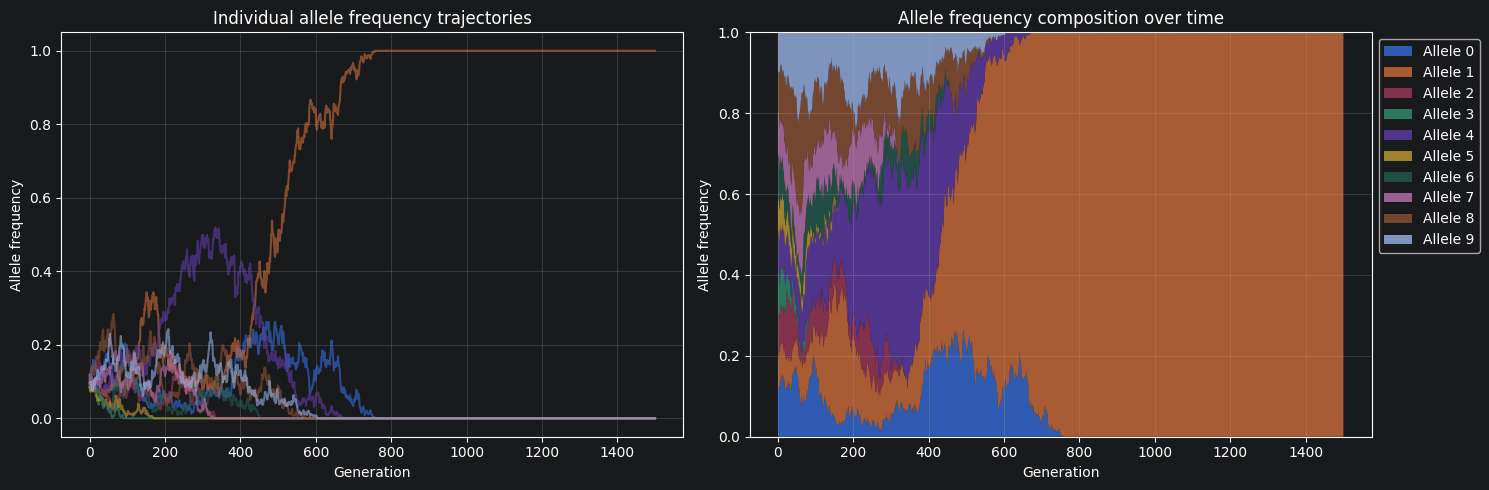

In [24]:
# Simulation and visualisation
current_generation = initialize_population(N, allele_initial_frequencies, rng)

generations = [0]
allele_frequencies_in_time = [
    calculate_allele_frequencies(current_generation)
]

for t in range(1, T + 1):
    current_generation = next_generation(current_generation, rng)

    allele_frequencies_in_time.append(
        calculate_allele_frequencies(current_generation)
    )
    generations.append(t)

allele_frequencies_in_time = np.array(allele_frequencies_in_time)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))


for i in range(K):
    axes[0].plot(
        generations,
        allele_frequencies_in_time[:, i],
        alpha=0.6,
        label=f"Allele {i}"
    )

axes[0].set_xlabel("Generation")
axes[0].set_ylabel("Allele frequency")
axes[0].set_title("Individual allele frequency trajectories")
axes[0].grid(alpha=0.3)

axes[1].stackplot(
    generations,
    allele_frequencies_in_time.T,
    labels=[f"Allele {i}" for i in range(K)],
    alpha=0.8
)

axes[1].set_xlabel("Generation")
axes[1].set_ylabel("Allele frequency")
axes[1].set_title("Allele frequency composition over time")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.3)

axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()


## Evolution of genetic diversity

### Genetic diversity

Genetic diversity is quantified using gene diversity, defined as the probability that two independently sampled gene copies carry different alleles.

For a population with $K$ alleles, this quantity is given by:

$
H(t)=1-\sum_{i=1}^{K}x_i(t)^2.
$

This measure ranges from 0 to a maximum value of $1-1/K$, reached when all alleles are equally frequent.

- $H(t)=0$ corresponds to a monomorphic population, in which only one allele remains.
- Higher values indicate greater genetic diversity.

Under the neutral Wright-Fisher model, genetic diversity is expected to decrease over time due to random genetic drift.

### Theoretical expectation of genetic diversity

Under the neutral Wright-Fisher model, genetic diversity is expected to decrease over generations due to genetic drift.

At each generation, allele frequencies are subject to multinomial sampling. The conditional expectation of genetic diversity in the next generation is therefore:

$
\mathbb{E}[H(t+1)\mid\mathbf p(t)]
=
\left(1-\frac{1}{N}\right)H(t)
$

Taking the expectation over all possible population states, this gives:

$
\mathbb{E}[H(t)]
=
H(0)\left(1-\frac{1}{N}\right)^t
$

Thus, genetic diversity is expected to decrease exponentially over time, with a rate of decline that depends on population size. Smaller populations experience faster loss of genetic diversity due to stronger genetic drift.

In [10]:
def calculate_diversity(allele_counts: np.ndarray) -> float:
    """
    Calculate gene diversity from allele counts.

    Gene diversity is the probability that two randomly
    sampled alleles differ.
    """
    allele_frequencies = calculate_allele_frequencies(allele_counts)
    return 1 - np.sum(allele_frequencies**2)


def calculate_theoretical_diversity(
    initial_diversity: float,
    population_size: int,
    generations: int
) -> float:
    """
    Calculate the expected gene diversity under neutral
    Wright-Fisher drift.
    """
    return initial_diversity * (
        1 - 1 / population_size
    ) ** generations


In [25]:
# Parameters
N = 1000
K = 10
T = 3000
number_of_simulations = 200

allele_initial_frequencies = [1/K] * K

seed = 42
rng = np.random.default_rng(seed)

In [26]:
# Simulation and visualisation
initial_population = initialize_population(N, allele_initial_frequencies, rng)

initial_diversity = calculate_diversity(initial_population)

diversity_replicates = []

for replicate in range(number_of_simulations):

    current_generation = initial_population.copy()

    diversity_trajectory = [initial_diversity]

    for t in range(1, T + 1):
        current_generation = next_generation(current_generation, rng)
        diversity_trajectory.append(calculate_diversity(current_generation))

    diversity_replicates.append(diversity_trajectory)


diversity_replicates = np.array(diversity_replicates)

mean_diversity = np.mean(diversity_replicates, axis=0)

theoretical_values = np.array([
    calculate_theoretical_diversity(initial_diversity, N, t)
    for t in range(T + 1)
])

lower_quantile = np.quantile(diversity_replicates, 0.05, axis=0)
upper_quantile = np.quantile(diversity_replicates, 0.95, axis=0)

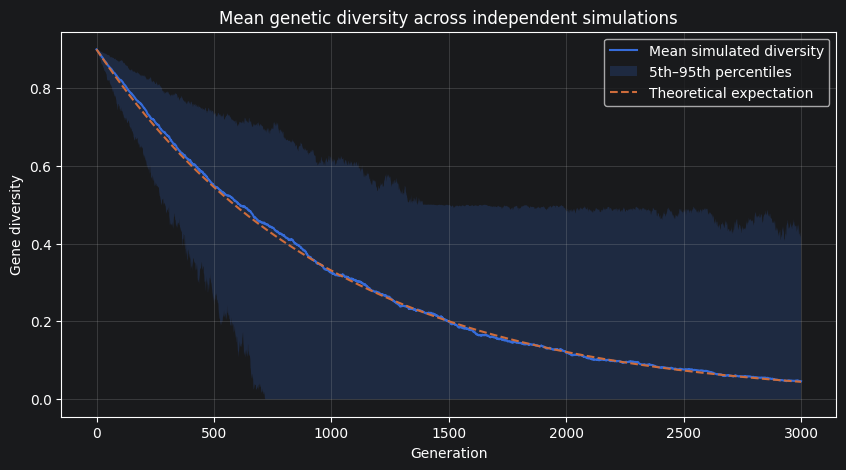

In [27]:
generations = np.arange(T + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    generations,
    mean_diversity,
    label="Mean simulated diversity"
)

plt.fill_between(
    generations,
    lower_quantile,
    upper_quantile,
    alpha=0.2,
    label="5th–95th percentiles"
)

plt.plot(
    generations,
    theoretical_values,
    "--",
    label="Theoretical expectation"
)

plt.xlabel("Generation")
plt.ylabel("Gene diversity")
plt.title("Mean genetic diversity across independent simulations")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Influence of population size

In [28]:
# Parameters
population_sizes = [50, 100, 500, 1000]
K = 10
T = 3000

allele_initial_frequencies = [1/K] * K

seed = 42
rng = np.random.default_rng(seed)

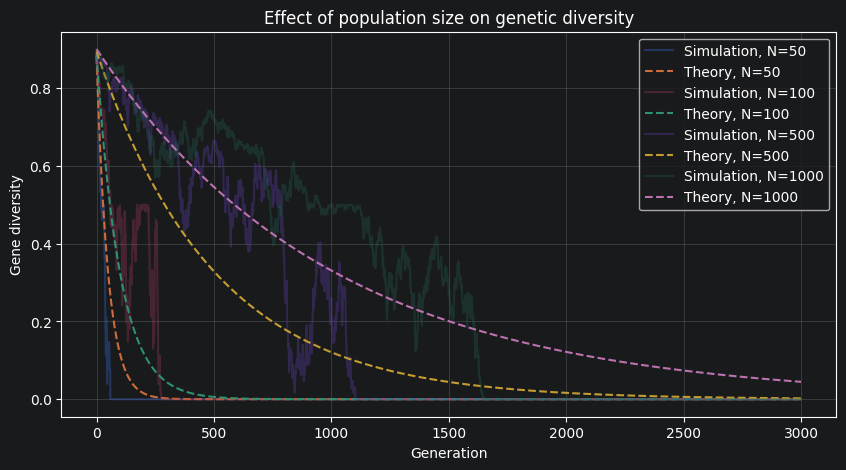

In [29]:
# Simulation
generations = np.arange(T + 1)

plt.figure(figsize=(10, 5))

for N in population_sizes:

    current_generation = initialize_population(
        N, allele_initial_frequencies, rng
    )

    initial_diversity = calculate_diversity(current_generation)

    diversity_trajectory = [initial_diversity]

    for t in range(1, T + 1):
        current_generation = next_generation(current_generation, rng)
        diversity_trajectory.append(calculate_diversity(current_generation))

    theoretical_values = [
        calculate_theoretical_diversity(initial_diversity, N, t)
        for t in generations
    ]

    plt.plot(
        generations,
        diversity_trajectory,
        alpha=0.35,
        label=f"Simulation, N={N}"
    )

    plt.plot(
        generations,
        theoretical_values,
        "--",
        label=f"Theory, N={N}"
    )

plt.xlabel("Generation")
plt.ylabel("Gene diversity")
plt.title("Effect of population size on genetic diversity")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Characteristic time of genetic diversity decay

Under the neutral haploid Wright-Fisher model, the expected gene diversity after $t$ generations is:

$
\mathbb{E}[H(t)] = H(0)\left(1-\frac{1}{N}\right)^t
$

This can be expressed as an exponential decay:

$
\mathbb{E}[H(t)] = H(0)e^{-t/\tau}
$

where the characteristic time is:

$
\boxed{\tau = -\frac{1}{\ln(1-1/N)}}
$

For large population sizes:

$
\tau \approx N
$

The characteristic time $tau$ is the number of generations required for expected genetic diversity to fall to approximately $1/e$, or 36.8%, of its initial value.

Therefore, genetic diversity is lost more rapidly in smaller populations, where genetic drift is stronger.

## Absorption time

In a population with two alleles and no mutation, genetic drift eventually leads to the loss of one allele and the fixation of the other. This state is called *absorption*.

The time to absorption is the number of generations required to reach either of these two outcomes.

For a neutral haploid Wright-Fisher population, the diffusion approximation gives the following expected time to absorption:

$
\mathbb{E}[T_{\mathrm{abs}}]
\approx
$

where $p$ is the initial frequency of one of the two alleles.

For equal initial frequencies $p=0.5$:

$
\mathbb{E}[T_{\mathrm{abs}}]\approx 2N\ln(2)
$

Thus, the expected time to absorption also increases approximately linearly with population size.

**Important distinction:** the characteristic time of diversity decay is not the time to fixation. Diversity decreases progressively, whereas absorption occurs only when one allele has been completely lost. The two quantities describe different aspects of genetic drift.

In [38]:
# Parameters
population_sizes = [50, 100, 200]
number_of_simulations = 1000
max_generations = 10000

seed = 42
rng = np.random.default_rng(seed)

In [39]:
def simulate_until_absorption(
    initial_counts: np.ndarray,
    rng,
    max_generations: int
):
    """
    Simulate genetic drift until the population becomes monomorphic
    or the maximum number of generations is reached.

    Returns:
        absorption_time: number of generations
        fixed_allele: index of the fixed allele, or -1 if not absorbed
    """
    current_generation = initial_counts.copy()
    population_size = np.sum(current_generation)

    t = 0

    while np.max(current_generation) < population_size and t < max_generations:
        current_generation = next_generation(current_generation, rng)
        t += 1

    if np.max(current_generation) == population_size:
        fixed_allele = np.argmax(current_generation)
    else:
        fixed_allele = -1

    return t, fixed_allele


In [40]:
absorption_times = {}

for N in population_sizes:

    initial_counts = np.array([N // 2, N - N // 2])

    times = []
    non_absorbed = 0

    for replicate in range(number_of_simulations):

        absorption_time, fixed_allele = simulate_until_absorption(
            initial_counts,
            rng,
            max_generations
        )

        if fixed_allele != -1:
            times.append(absorption_time)
        else:
            non_absorbed += 1

    absorption_times[N] = times

    print(
        f"N = {N}: mean absorption time = {np.mean(times):.1f} generations "
        f"({len(times)} completed, {non_absorbed} not absorbed)"
    )


N = 50: mean absorption time = 68.6 generations (1000 completed, 0 not absorbed)
N = 100: mean absorption time = 134.9 generations (1000 completed, 0 not absorbed)
N = 200: mean absorption time = 277.8 generations (1000 completed, 0 not absorbed)


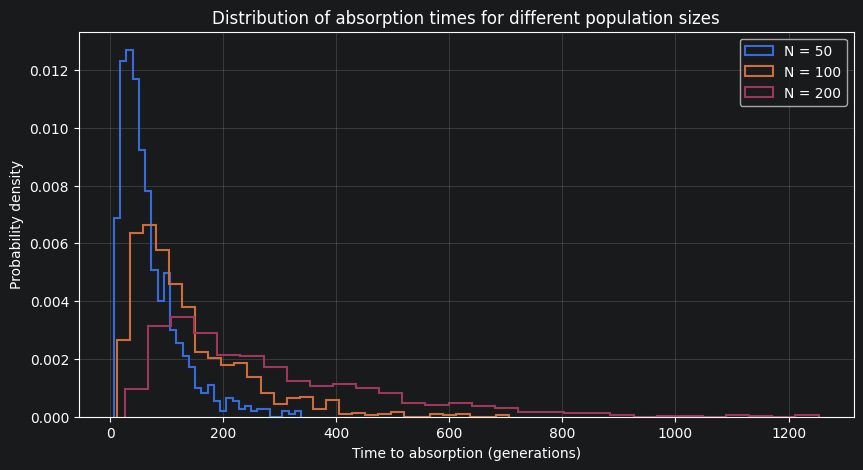

In [41]:

plt.figure(figsize=(10, 5))

for N in population_sizes:

    plt.hist(
        absorption_times[N],
        bins=30,
        density=True,
        histtype="step",
        linewidth=1.5,
        label=f"N = {N}"
    )

plt.xlabel("Time to absorption (generations)")
plt.ylabel("Probability density")
plt.title("Distribution of absorption times for different population sizes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [42]:

for N in population_sizes:

    simulated_mean = np.mean(absorption_times[N])
    theoretical_mean = 2 * N * np.log(2)

    print(
        f"N = {N:4d} | "
        f"Simulated mean = {simulated_mean:.1f} | "
        f"Theoretical mean ≈ {theoretical_mean:.1f}"
    )


N =   50 | Simulated mean = 68.6 | Theoretical mean ≈ 69.3
N =  100 | Simulated mean = 134.9 | Theoretical mean ≈ 138.6
N =  200 | Simulated mean = 277.8 | Theoretical mean ≈ 277.3


### Conclusion

These simulations illustrate two important consequences of genetic drift in finite populations.

First, genetic diversity decreases over time, with a rate that depends on population size. The characteristic time of diversity decay is approximately equal to the population size \(N\).

Second, in the absence of mutation, genetic drift eventually leads to the loss of all but one allele. The time required to reach this absorbing state increases with population size and is variable across independent simulations.

Together, these results show that genetic drift has a stronger and faster impact in small populations, where both genetic diversity and the persistence of polymorphism are more limited.